In [2]:
!pip install xgboost

In [3]:
#============================ Loading required libraries ============================#
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import seaborn
from sklearn.metrics import confusion_matrix, classification_report, precision_score, recall_score, f1_score, roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

In [4]:
#============================ Loading Healthy Reference Baseline & Merging 5 Disease Datasets ============================#
import os

# 1. Load the 4 Uploaded Healthy Reference Baseline Datasets (N = 7,000, Tier 0 Controls)
HEALTHY_REFERENCE_FILES = {
    'general': 'caregrid_healthy_general_1750.csv',
    'heart_attack': 'caregrid_healthy_heart_attack_1750.csv',
    'palpitations': 'caregrid_healthy_palpitations_1750.csv',
    'stroke': 'caregrid_healthy_stroke_1750.csv'
}

df_healthy_ref = pd.concat([pd.read_csv(f) for f in HEALTHY_REFERENCE_FILES.values() if os.path.exists(f)], ignore_index=True)
df_healthy_ref['chol'] = df_healthy_ref['hdl_mg_dl'] + df_healthy_ref['ldl_mg_dl'] + 20.0

# Compute Healthy Reference Standard (Mean & SD) for each physiological feature
ref_col_map = {
    'age': 'age_years',
    'trestbps': 'systolic_bp_mmhg',
    'diastolic_bp': 'diastolic_bp_mmhg',
    'chol': 'chol',
    'thalch': 'heart_rate_bpm',
    'spo2': 'spo2_percent',
    'temp_c': 'temperature_c',
    'resp_rate': 'respiratory_rate_bpm',
    'hr_change': 'hr_change_bpm_per_interval',
    'hr_rolling_sd': 'hr_rolling_sd_bpm',
    'hr_rolling_cv': 'hr_rolling_cv',
    'spo2_change': 'spo2_change_pct_points_per_interval',
    'spo2_rolling_sd': 'spo2_rolling_sd_pct_points',
    'glucose': 'glucose_mg_dl',
    'bmi': 'bmi_kg_m2'
}

HEALTHY_BASELINE_STATS = {}
for target_col, ref_col in ref_col_map.items():
    s = pd.to_numeric(df_healthy_ref[ref_col], errors='coerce').dropna()
    HEALTHY_BASELINE_STATS[target_col] = {
        'mean': float(s.mean()),
        'std': float(max(s.std(), 1e-4)),
        'min': float(s.min()),
        'max': float(s.max())
    }

# Add UCI normal controls (num == 0) for exercise ECG parameters ('oldpeak' & peak exercise 'thalch')
df_uci = pd.read_csv('heart_disease_uci.csv')
uci_norm = df_uci[df_uci['num'] == 0]
HEALTHY_BASELINE_STATS['oldpeak'] = {
    'mean': float(uci_norm['oldpeak'].dropna().mean()),
    'std': float(uci_norm['oldpeak'].dropna().std())
}
HEALTHY_BASELINE_STATS['uci_peak_thalch'] = {
    'mean': float(uci_norm['thalch'].dropna().mean()),
    'std': float(uci_norm['thalch'].dropna().std())
}

# 2. Load & Align the 5 Disease Datasets (N = 7,920)
df_gen = pd.read_csv('caregrid_general_combined(caregrid_general_combined).csv')
df_ha = pd.read_csv('caregrid_heart_attack_1750(caregrid_heart_attack_1750).csv')
df_palp = pd.read_csv('caregrid_palpitations_1750(caregrid_palpitations_1750).csv')
df_stroke = pd.read_csv('caregrid_stroke_1750(caregrid_stroke_1750).csv')

# 1. UCI Heart Disease (920 rows)
uci_clean = pd.DataFrame({
    'age': df_uci['age'].astype(float),
    'sex': df_uci['sex'],
    'cp': df_uci['cp'],
    'trestbps': df_uci['trestbps'].replace(0, np.nan).astype(float),
    'chol': df_uci['chol'].replace(0, np.nan).astype(float),
    'fbs': df_uci['fbs'].map({True: True, False: False, 'TRUE': True, 'FALSE': False}),
    'restecg': df_uci['restecg'],
    'thalch': df_uci['thalch'].astype(float),
    'exang': df_uci['exang'].map({True: True, False: False, 'TRUE': True, 'FALSE': False}),
    'oldpeak': df_uci['oldpeak'].astype(float),
    'slope': df_uci['slope'],
    'ca': df_uci['ca'].astype(float),
    'thal': df_uci['thal'],
    'cohort_id': 0,
    'disease_present': df_uci['num'].map({0: 0, 1: 1, 2: 1, 3: 1, 4: 1}).astype(int)
})

# 2. CareGrid General Vitals (1,750 rows)
gen_clean = pd.DataFrame({
    'trestbps': df_gen['systolic_bp_mmhg'].astype(float),
    'diastolic_bp': df_gen['diastolic_bp_mmhg'].astype(float),
    'thalch': df_gen['heart_rate_bpm'].astype(float),
    'spo2': df_gen['spo2_percent'].astype(float),
    'temp_c': df_gen['temperature_c'].apply(lambda t: (t - 32.0) * 5.0 / 9.0 if t > 50 else t).astype(float),
    'resp_rate': df_gen['respiratory_rate_bpm'].astype(float),
    'cohort_id': 1,
    'disease_present': (df_gen['tier_level'] > 1).astype(int)
})

# 3. CareGrid Heart Attack Telemetry (1,750 rows)
ha_clean = pd.DataFrame({
    'thalch': df_ha['heart_rate_bpm'].astype(float),
    'spo2': df_ha['spo2_percent'].astype(float),
    'hr_change': df_ha['hr_change_bpm_per_interval'].astype(float),
    'hr_rolling_sd': df_ha['hr_rolling_sd_bpm'].astype(float),
    'hr_rolling_cv': df_ha['hr_rolling_cv'].astype(float),
    'spo2_change': df_ha['spo2_change_pct_points_per_interval'].astype(float),
    'spo2_rolling_sd': df_ha['spo2_rolling_sd_pct_points'].astype(float),
    'time_index': df_ha['time_index'].astype(float),
    'condition_label': df_ha['condition_label'],
    'cohort_id': 2,
    'disease_present': df_ha['event_label'].astype(int)
})

# 4. CareGrid Palpitations (1,750 rows)
palp_clean = pd.DataFrame({
    'age': df_palp['age_years'].astype(float),
    'sex': df_palp['sex'].map({1: 'Male', 0: 'Female'}),
    'cp': np.where(df_palp['chest_pain_flag'] == 1, 'typical angina', 'asymptomatic'),
    'fbs': (df_palp['diabetes_flag'] == 1),
    'cohort_id': 3,
    'disease_present': df_palp['heart_risk_flag'].astype(int)
})
for c in ['hypertension_flag', 'high_cholesterol_flag', 'shortness_of_breath_flag',
          'chest_pain_flag', 'fatigue_flag', 'dizziness_flag', 'swelling_flag',
          'pain_arms_jaw_back_flag', 'cold_sweats_nausea_flag', 'obesity_flag',
          'sedentary_lifestyle_flag', 'family_history_flag', 'chronic_stress_flag',
          'palpitations_symptom_flag']:
    palp_clean[c] = df_palp[c].astype(float)

# 5. CareGrid Stroke (1,750 rows)
sym_series = df_stroke['symptoms_or_signs'].fillna('')
stroke_clean = pd.DataFrame({
    'age': df_stroke['age_years'].astype(float),
    'sex': df_stroke['sex'],
    'trestbps': df_stroke['systolic_bp_mmhg'].astype(float),
    'diastolic_bp': df_stroke['diastolic_bp_mmhg'].astype(float),
    'chol': (df_stroke['hdl_mg_dl'] + df_stroke['ldl_mg_dl'] + 20.0).astype(float),
    'fbs': (df_stroke['glucose_mg_dl'] >= 126.0),
    'glucose': df_stroke['glucose_mg_dl'].astype(float),
    'bmi': df_stroke['bmi_kg_m2'].astype(float),
    'hypertension_flag': df_stroke['hypertension_flag'].astype(float),
    'stroke_history_flag': df_stroke['stroke_history_flag'].astype(float),
    'symptoms_or_signs': df_stroke['symptoms_or_signs'],
    'symptom_count': sym_series.apply(lambda s: 0.0 if s.strip() == '' else float(len(set(x.strip().lower() for x in s.split(',') if x.strip())))),
    'cohort_id': 4,
    'disease_present': (df_stroke['tier_level'] > 1).astype(int)
})

# Keep un-imputed copy (df_raw_merged) for exact 3-Tier Behavioral & Vital Marker Extraction
df_raw_merged = pd.concat([uci_clean, gen_clean, ha_clean, palp_clean, stroke_clean], ignore_index=True)

# Combine all 5 datasets for EDA & ML cells and keep 'disease_present' as the last column
df = df_raw_merged.drop(columns=['time_index', 'condition_label', 'symptoms_or_signs'], errors='ignore').copy()
cols = [c for c in df.columns if c != 'disease_present'] + ['disease_present']
df = df[cols]
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,...,obesity_flag,sedentary_lifestyle_flag,family_history_flag,chronic_stress_flag,palpitations_symptom_flag,glucose,bmi,stroke_history_flag,symptom_count,disease_present
0,63.0,Male,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,67.0,Male,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2,67.0,Male,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,37.0,Male,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,41.0,Female,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


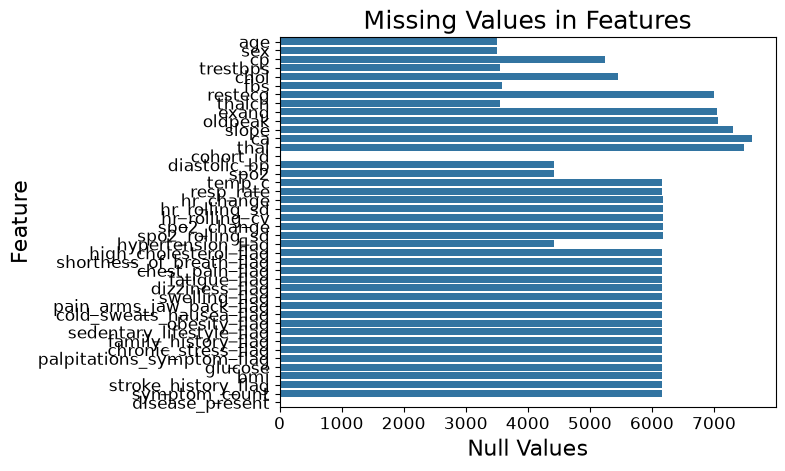

In [5]:
#============================ Missing Value Treatment ============================#

# Counting null values in each feature
df_null = pd.DataFrame(df.isnull().sum().reset_index())
df_null.columns = ['feature', 'null_values']
df_null

# Barchart for null values
sns.barplot(y=df_null['feature'], x=df_null['null_values'], orient='h')
plt.title('Missing Values in Features', fontsize=18)
plt.xlabel('Null Values', fontsize=16)
plt.ylabel('Feature', fontsize=16)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()


In [6]:
# For Categorical features, replacing null values using Healthy Reference normal baseline defaults
df = df.sample(frac=1, random_state=0)
df_raw_merged = df_raw_merged.loc[df.index].reset_index(drop=True)
df = df.reset_index(drop=True)

healthy_cat_defaults = {
    'sex': 'Male',
    'cp': 'asymptomatic',
    'restecg': 'normal',
    'fbs': False,
    'exang': False,
    'slope': 'upsloping',
    'thal': 'normal'
}
for c, default_val in healthy_cat_defaults.items():
    df[c] = df[c].fillna(default_val)
df.isnull().sum()

age                          3500
sex                             0
cp                              0
trestbps                     3560
chol                         5452
fbs                             0
restecg                         0
thalch                       3555
exang                           0
oldpeak                      7062
slope                           0
ca                           7611
thal                            0
cohort_id                       0
diastolic_bp                 4420
spo2                         4420
temp_c                       6170
resp_rate                    6170
hr_change                    6171
hr_rolling_sd                6171
hr_rolling_cv                6171
spo2_change                  6171
spo2_rolling_sd              6171
hypertension_flag            4420
high_cholesterol_flag        6170
shortness_of_breath_flag     6170
chest_pain_flag              6170
fatigue_flag                 6170
dizziness_flag               6170
swelling_flag 

In [7]:
# For Numerical features, replacing null values with the Healthy Reference Baseline Mean
num_cols = [c for c in df.columns if c not in ['sex', 'cp', 'restecg', 'fbs', 'exang', 'slope', 'thal', 'disease_present']]
for c in num_cols:
    ref_mean = HEALTHY_BASELINE_STATS.get(c, {}).get('mean', 0.0)
    df[c] = pd.to_numeric(df[c], errors='coerce').fillna(ref_mean)
df.isnull().sum()

age                          0
sex                          0
cp                           0
trestbps                     0
chol                         0
fbs                          0
restecg                      0
thalch                       0
exang                        0
oldpeak                      0
slope                        0
ca                           0
thal                         0
cohort_id                    0
diastolic_bp                 0
spo2                         0
temp_c                       0
resp_rate                    0
hr_change                    0
hr_rolling_sd                0
hr_rolling_cv                0
spo2_change                  0
spo2_rolling_sd              0
hypertension_flag            0
high_cholesterol_flag        0
shortness_of_breath_flag     0
chest_pain_flag              0
fatigue_flag                 0
dizziness_flag               0
swelling_flag                0
pain_arms_jaw_back_flag      0
cold_sweats_nausea_flag      0
obesity_

In [8]:
#============================ Visualizations ============================#

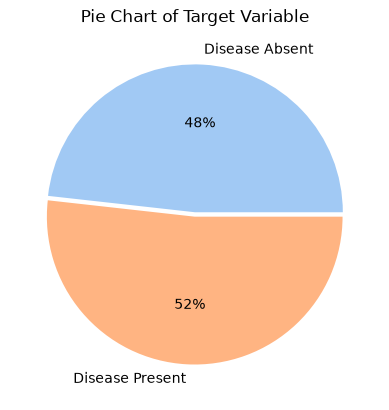

In [9]:
# Pie-chart of Target feature - disease_present

unique_values = df['disease_present'].unique()
counts = df['disease_present'].value_counts().sort_values()
percentages = counts / counts.sum() * 100
plt.pie(percentages, labels=['Disease Absent', 'Disease Present'],
        colors= seaborn.color_palette('pastel'), explode=[0.02,0.01], autopct='%.0f%%')
plt.title('Pie Chart of Target Variable')
plt.show()

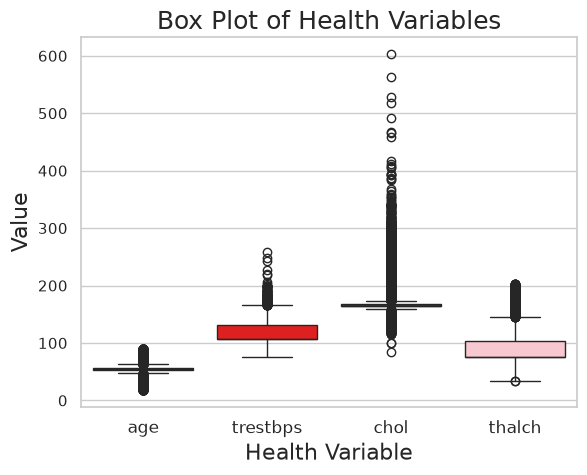

In [10]:
#============================ Box Plot of Health Variables ============================#

# Select variables for box plots
health_variables = ['age', 'trestbps', 'chol', 'thalch']

# Define colors for each variable
colors = ['blue', 'red', 'purple', 'pink']

# Set the Seaborn style
sns.set(style="whitegrid")

# Create a box plot using Seaborn
#plt.figure(figsize=(15, 10))
ax = sns.boxplot(data=df[health_variables], palette=colors)

# Set x-axis ticks and labels with rotation
ax.set_xticks(range(len(health_variables)))
ax.set_xticklabels(health_variables, fontsize=12)

# Set labels and title
ax.set_xlabel('Health Variable', fontsize=16)
ax.set_ylabel('Value', fontsize=16)
ax.set_title('Box Plot of Health Variables', fontsize=18)

plt.show()

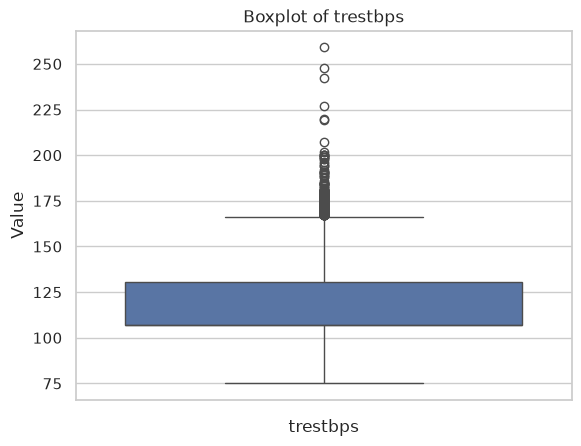

In [11]:
# Boxplot for any numerical feature
numerical_features = ['age', 'trestbps', 'chol', 'fbs', 'exang', 'oldpeak', 'thalch']
feature = 'trestbps'
sns.boxplot( y=df[feature] );
plt.xlabel(feature)
plt.ylabel('Value')
plt.title('Boxplot of {}'.format(feature))
plt.show()

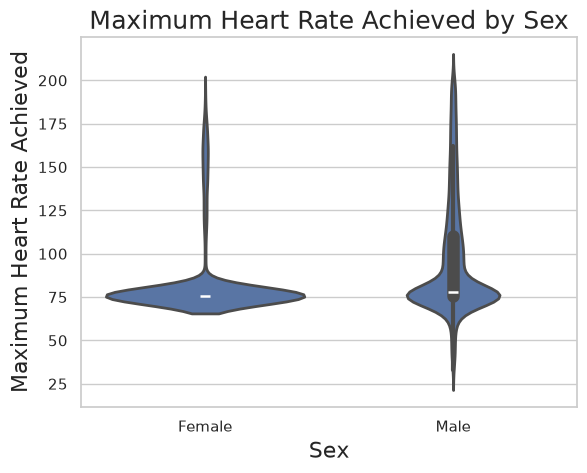

In [12]:
# Violin Plot of Maximum Heart Rate Achieved
import seaborn

# use to set style of background of plot
seaborn.set(style="whitegrid")

ax = seaborn.violinplot(x=df["sex"], y=df["thalch"], linewidth = 2)

ax.set_xlabel('Sex', fontsize=16)
ax.set_ylabel('Maximum Heart Rate Achieved', fontsize=16)
ax.set_title('Maximum Heart Rate Achieved by Sex', fontsize=18)

plt.show()

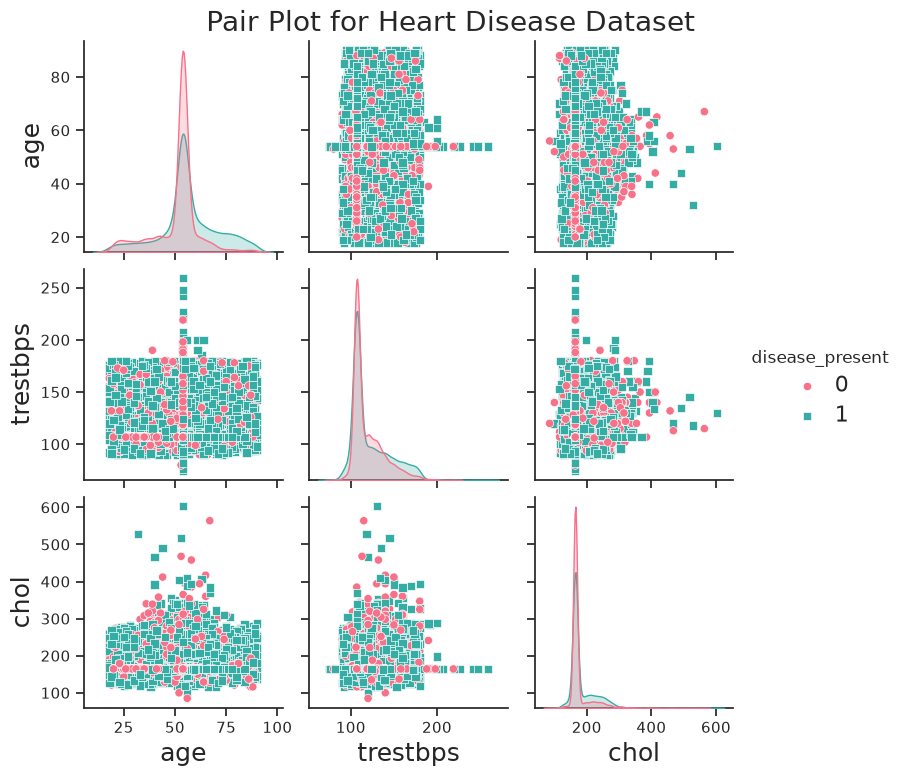

In [13]:
#============================ Pair Plot ============================#

# Select specific columns
selected_columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'disease_present']

# Create a copy of the subset
df_subset = df[selected_columns].copy()

# Convert categorical variables to appropriate data types
df_subset['sex'] = df_subset['sex'].astype('category')
df_subset['cp'] = df_subset['cp'].astype('category')
df_subset['disease_present'] = df_subset['disease_present'].astype('category')

# Create a pair plot for multivariate EDA
sns.set(style="ticks", color_codes=True)
pair_plot = sns.pairplot(df_subset, hue='disease_present', palette='husl', markers=["o", "s"])

# Add a title to the pair plot
pair_plot.fig.suptitle("Pair Plot for Heart Disease Dataset", y=1.02, fontsize=20)

legend = pair_plot._legend
for text in legend.get_texts():
    text.set_fontsize(16)

# Loop through each subplot to set x and y labels
for ax in pair_plot.axes.flatten():
    ax.set_xlabel(ax.get_xlabel(), fontsize=18)  # Increase x-axis label font size
    ax.set_ylabel(ax.get_ylabel(), fontsize=18)  # Increase y-axis label font size

# Show the plot
plt.show()

In [14]:
#============================ Data Transformation for Modeling ============================#

# Label Encoding for categorical features
label_encoder = LabelEncoder()
df['cp'] = label_encoder.fit_transform(df['cp'])
df['restecg'] = label_encoder.fit_transform(df['restecg'])
df['slope'] = label_encoder.fit_transform(df['slope'])
df['thal'] = label_encoder.fit_transform(df['thal'])
df['fbs'] = label_encoder.fit_transform(df['fbs'])
df['exang'] = label_encoder.fit_transform(df['exang'])

df['sex']=df['sex'].replace(('Male','Female'),(1,0))
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,...,obesity_flag,sedentary_lifestyle_flag,family_history_flag,chronic_stress_flag,palpitations_symptom_flag,glucose,bmi,stroke_history_flag,symptom_count,disease_present
0,62.000000,0,0,155.000000,200.000000,1,1,75.7580,0,0.418205,...,0.0,0.0,0.0,0.0,0.0,133.0100,27.380000,1.0,0.0,0
1,53.000000,0,3,106.871143,164.374857,0,1,75.7580,0,0.418205,...,1.0,1.0,1.0,0.0,1.0,89.5932,22.457714,0.0,0.0,1
2,53.915143,1,0,148.000000,164.374857,0,1,92.0000,0,0.418205,...,0.0,0.0,0.0,0.0,0.0,89.5932,22.457714,0.0,0.0,0
3,57.000000,0,3,106.871143,164.374857,1,1,75.7580,0,0.418205,...,0.0,0.0,0.0,1.0,0.0,89.5932,22.457714,0.0,0.0,0
4,35.000000,1,0,118.000000,152.000000,1,1,75.7580,0,0.418205,...,0.0,0.0,0.0,0.0,0.0,162.0700,30.610000,1.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7915,65.000000,1,3,106.871143,164.374857,1,1,75.7580,0,0.418205,...,1.0,0.0,0.0,1.0,0.0,89.5932,22.457714,0.0,0.0,1
7916,53.915143,1,0,106.871143,164.374857,0,1,181.0490,0,0.418205,...,0.0,0.0,0.0,0.0,0.0,89.5932,22.457714,0.0,0.0,1
7917,53.915143,1,0,118.927000,164.374857,0,1,75.6072,0,0.418205,...,0.0,0.0,0.0,0.0,0.0,89.5932,22.457714,0.0,0.0,0
7918,53.915143,1,0,124.000000,164.374857,0,1,89.0000,0,0.418205,...,0.0,0.0,0.0,0.0,0.0,89.5932,22.457714,0.0,0.0,1


In [15]:
df.to_csv('final_data.csv', index = False)

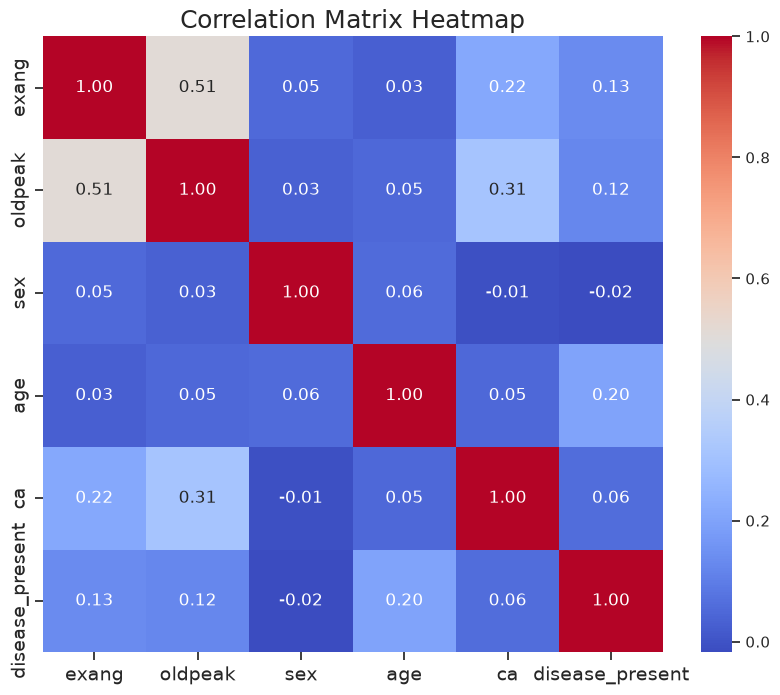

In [16]:
#============================ Correlation Matrix Heatmap ============================#
features_analysis=['exang', 'oldpeak', 'sex', 'age', 'ca', 'disease_present']
# features_analysis=['age', 'sex', 'trestbps', 'oldpeak', 'disease_present']
# features_analysis = df.columns
for i in features_analysis:
    df[i] = pd.to_numeric(df[i], errors='coerce')

subset_data = df[features_analysis]

correlation_matrix = subset_data.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix Heatmap", fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

In [17]:
#===============================================================================#
#============================ Classification Models ============================#
#===============================================================================#

In [18]:
#============================ Scaling the data using standard scaler ============================#

In [19]:
df = pd.read_csv('final_data.csv')
feature_cols = [c for c in df.columns if c != 'disease_present']

X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

# Build the 7,000-row Healthy Reference feature matrix aligned to 'feature_cols'
df_ref_aligned = pd.DataFrame(index=df_healthy_ref.index)
for col in feature_cols:
    if col in ref_col_map and ref_col_map[col] in df_healthy_ref.columns:
        df_ref_aligned[col] = pd.to_numeric(df_healthy_ref[ref_col_map[col]], errors='coerce').fillna(
            HEALTHY_BASELINE_STATS[col]['mean']
        )
    elif col in df_healthy_ref.columns:
        df_ref_aligned[col] = pd.to_numeric(df_healthy_ref[col], errors='coerce').fillna(0.0)
    else:
        df_ref_aligned[col] = HEALTHY_BASELINE_STATS.get(col, {}).get('mean', 0.0)

sc = StandardScaler()
# Fit StandardScaler on the 7,000 Healthy Reference controls + healthy training controls
sc.fit(np.vstack([df_ref_aligned.values, X_train[y_train == 0]]))

X_train = sc.transform(X_train)
X_test = sc.transform(X_test)

In [20]:
#============================ Support Vector Machine (SVM) ============================#


Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.94      0.89       759
           1       0.94      0.83      0.88       825

    accuracy                           0.89      1584
   macro avg       0.89      0.89      0.89      1584
weighted avg       0.89      0.89      0.88      1584

Metrics for Test Set:
Accuracy: 0.88510101010101


Text(90.97222222222221, 0.5, 'Predicted')

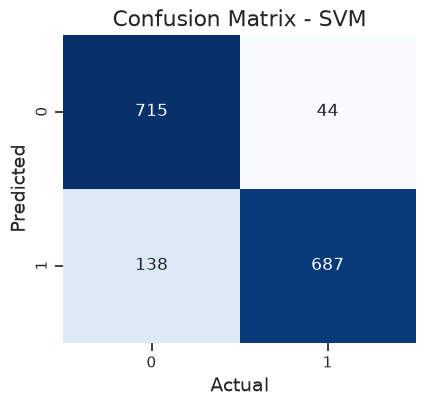

In [21]:
classifier = SVC(kernel='rbf')
classifier.fit(X_train, y_train)

# Predicting the Test set results
y_pred = classifier.predict(X_test)
cm_test = confusion_matrix(y_test, y_pred)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

precision_test = precision_score(y_test, y_pred)
recall_test = recall_score(y_test, y_pred)
f1_test = f1_score(y_test, y_pred)

print('Metrics for Test Set:')
print('Accuracy: {}'.format((cm_test[0][0] + cm_test[1][1]) / len(y_test)))

# Plot Confusion Matrices
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix - SVM', fontsize = 16)
plt.xlabel('Actual', fontsize = 14)
plt.ylabel('Predicted', fontsize = 14)

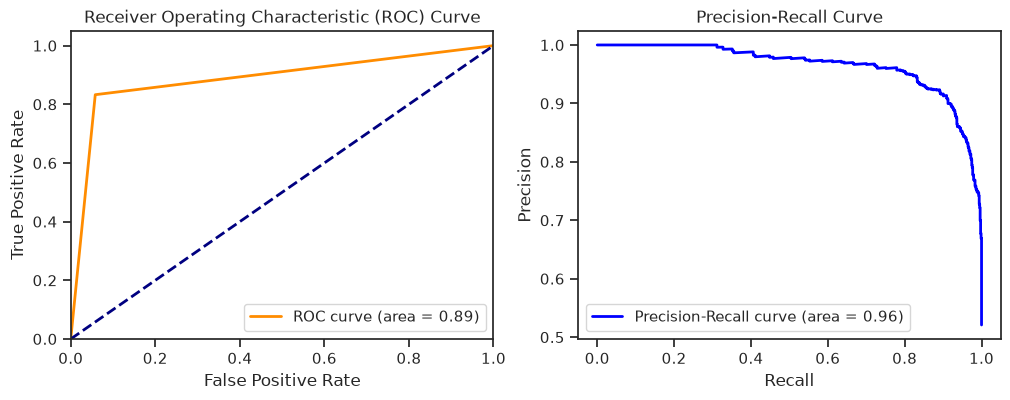

In [22]:
# ROC Curve for test set
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')

# Precision-Recall Curve of test set
precision, recall, thresholds = precision_recall_curve(y_test, classifier.decision_function(X_test))
area_under_curve = auc(recall, precision)

plt.subplot(1, 2, 2)
plt.plot(recall, precision, color='blue', lw=2, label='Precision-Recall curve (area = {:.2f})'.format(area_under_curve))
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.show()

In [23]:
#============================ Logistic Regression  ============================#

Accuracy for test set for Logistic Regression = 88.51%

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.93      0.89       759
           1       0.93      0.84      0.88       825

    accuracy                           0.89      1584
   macro avg       0.89      0.89      0.89      1584
weighted avg       0.89      0.89      0.89      1584



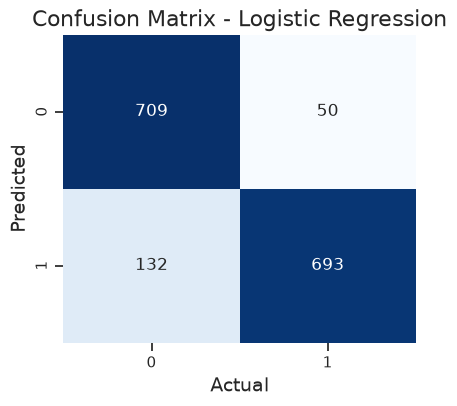

In [24]:
classifier = LogisticRegression()
classifier.fit(X_train, y_train)

# predictions(Test Set)
y_pred = classifier.predict(X_test)

# confusion matrix(Test Set)
cm_test = confusion_matrix(y_test, y_pred)

# predictions(Training Set)
y_pred_train = classifier.predict(X_train)

# confusion matrix(Training Set)
cm_train = confusion_matrix(y_pred_train, y_train)

# print the accuracy
#print('Accuracy for training set for Logistic Regression = {:.2%}'.format((cm_train[0][0] + cm_train[1][1])/len(y_train)))
print('Accuracy for test set for Logistic Regression = {:.2%}'.format((cm_test[0][0] + cm_test[1][1])/len(y_test)))

# classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# confusion matrix visualization
#plt.figure(figsize=(12, 4))
#plt.subplot(1, 2, 1)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title('Confusion Matrix - Logistic Regression', fontsize = 16)
plt.xlabel('Actual', fontsize = 14)
plt.ylabel('Predicted', fontsize = 14)
# # ROC curve and AUC
# fpr, tpr, thresholds = roc_curve(y_test, y_pred)
# roc_auc = auc(fpr, tpr)

# plt.subplot(1, 2, 2)
# plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = {:.2f})'.format(roc_auc))
# plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
# plt.xlabel('False Positive Rate')
# plt.ylabel('True Positive Rate')
# plt.title('Receiver Operating Characteristic (ROC) Curve')
# plt.legend(loc='lower right')

# plt.tight_layout()
# plt.show()

# cross-validation
cv_scores = cross_val_score(classifier, X_train, y_train, cv=5)
#print("\nCross-Validation Scores:", cv_scores)
#print("Mean CV Accuracy: {:.2%}".format(cv_scores.mean()))

In [25]:
#============================ XGBoost ============================#

Accuracy for test set for XGBoost = 0.9267676767676768

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.93      0.92       759
           1       0.93      0.93      0.93       825

    accuracy                           0.93      1584
   macro avg       0.93      0.93      0.93      1584
weighted avg       0.93      0.93      0.93      1584



Text(90.97222222222221, 0.5, 'Predicted')

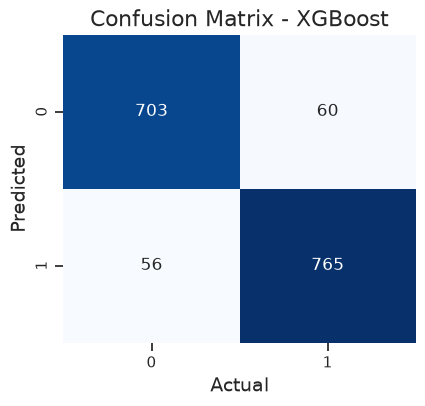

In [26]:
xg = XGBClassifier()
xg.fit(X_train, y_train)
y_pred = xg.predict(X_test)

cm_test = confusion_matrix(y_pred, y_test)
#print("confusion matrix for test set", cm_test)
TP = cm_test[1, 1]  # True Positives
FP = cm_test[0, 1]  # False Positives
TN = cm_test[0, 0]  # True Negatives
FN = cm_test[1, 0]  # False Negatives

precision = TP/(TP+FP)
recall = TP/(TP+FN)
print("Accuracy for test set for XGBoost =", (TN + TP)/len(y_test))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
y_pred_train = xg.predict(X_train)

for i in range(0, len(y_pred_train)):
    if y_pred_train[i]>= 0.5:       # setting threshold to .5
       y_pred_train[i]=1
    else:
       y_pred_train[i]=0
        # Confusion Matrix Plot for Test & Training set
# Plot Confusion Matrices
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix - XGBoost', fontsize = 16)
plt.xlabel('Actual', fontsize = 14)
plt.ylabel('Predicted', fontsize = 14)

In [27]:
#============================ Visualizations comparing Classification Models ============================#

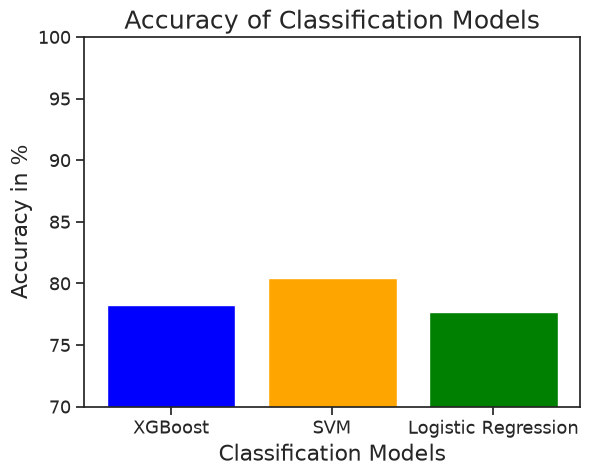

In [28]:
# Bar plot to compare accuracy of classifiers

# Accuracy scores of three models
models = ['XGBoost', 'SVM', 'Logistic Regression']
accuracy = [78.26, 80.43, 77.71]  # Replace these values with your accuracy scores

# Create bar chart
#plt.figure(figsize=(8, 6))
plt.bar(models, accuracy, color=['blue', 'orange', 'green'])

# Adding labels and title
plt.xlabel('Classification Models', fontsize=16)
plt.ylabel('Accuracy in %', fontsize=16)
plt.title('Accuracy of Classification Models', fontsize=18)
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)

# Show the plot
plt.ylim(70, 100)  # Set the y-axis limits
plt.show()


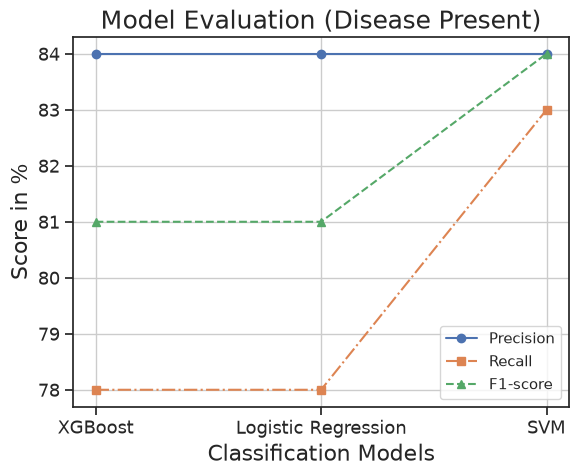

In [29]:
# Line chart to compare precision, recall and f1-score of classifiers (Class 1, Disease present)

# Precision, recall, and F1-scores of three models
models = ['XGBoost', 'Logistic Regression', 'SVM']
precision = [84, 84, 84]
recall = [78, 78, 83]
f1_scores = [81, 81, 84]

# Create line chart for precision
#plt.figure(figsize=(8, 6))
plt.plot(models, precision, marker='o', label='Precision', linestyle='-')

# Add line chart for recall
plt.plot(models, recall, marker='s', label='Recall', linestyle='-.')

# Add line chart for F1-score
plt.plot(models, f1_scores, marker='^', label='F1-score', linestyle='--')

# Adding labels and title
plt.xlabel('Classification Models', fontsize=16)
plt.ylabel('Score in %', fontsize=16)
plt.title('Model Evaluation (Disease Present)', fontsize=18)
plt.legend()  # Show legend
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)

# Show the plot
#plt.ylim(0, 1)  # Set the y-axis limits
plt.grid(True)  # Add gridlines
plt.show()


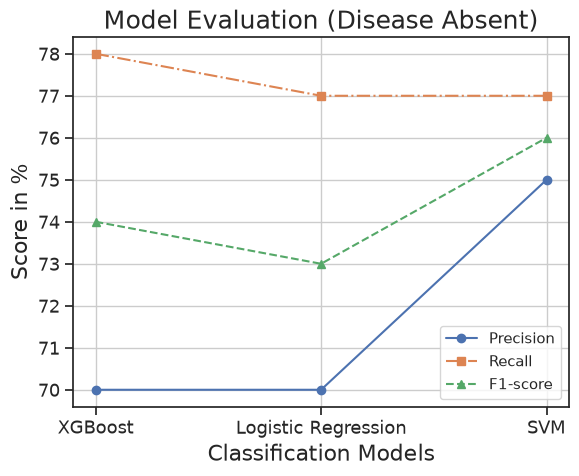

In [30]:
# Line chart to compare precision, recall and f1-score of classifiers (Class 0, Disease absent)

# Precision, recall, and F1-scores of three models
models = ['XGBoost', 'Logistic Regression', 'SVM']
precision = [70, 70, 75]
recall = [78, 77, 77]
f1_scores = [74, 73, 76]

# Create line chart for precision
#plt.figure(figsize=(8, 6))
plt.plot(models, precision, marker='o', label='Precision', linestyle='-')

# Add line chart for recall
plt.plot(models, recall, marker='s', label='Recall', linestyle='-.')

# Add line chart for F1-score
plt.plot(models, f1_scores, marker='^', label='F1-score', linestyle='--')

# Adding labels and title
plt.xlabel('Classification Models', fontsize=16)
plt.ylabel('Score in %', fontsize=16)
plt.title('Model Evaluation (Disease Absent)', fontsize=18)
plt.legend()  # Show legend
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)

# Show the plot
#plt.ylim(0, 1)  # Set the y-axis limits
plt.grid(True)  # Add gridlines
plt.show()


In [31]:
# ==============================================================================
# NEW CELL 1: 3-TIER CLINICAL SEVERITY & TRIAGE CLASSIFICATION ENGINE
# ==============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


class ClinicalSeverityTriageEngine:
    """
    Multi-Factor 3-Tier Clinical Severity & Triage Classification Engine.
    Classifies patient records into:
      - Tier 1: Least Severe / Low Risk
      - Tier 2: Intermediate / Moderate Risk
      - Tier 3: Life-Critical / High Risk / Emergency
    """

    TIER_LABELS = {
        1: "Tier 1: Least Severe / Low Risk",
        2: "Tier 2: Intermediate / Moderate Risk",
        3: "Tier 3: Life-Critical / High Risk / Emergency"
    }

    def __init__(self, uci_buggy_chol_value=132.13240418118466):
        self.uci_buggy_chol_value = uci_buggy_chol_value

    @staticmethod
    def _is_valid(val):
        return val is not None and not (isinstance(val, float) and np.isnan(val)) and pd.notnull(val)

    def evaluate_record(self, row, ml_pred=None, ml_prob=None):
        critical_triggers = []   # Direct Tier 3 triggers
        moderate_triggers = []   # Direct Tier 2 triggers
        minor_triggers = []      # Borderline / minor risk factors
        quality_flags = []       # Data hygiene & imputation flags
        physio_score = 0.0

        # 1. Explicit Database Severity Markers & Diagnosis Flags
        if self._is_valid(row.get('tier_level')):
            db_tier = int(round(float(row.get('tier_level'))))
            if db_tier == 3:
                critical_triggers.append("DB_SEVERITY_TIER_3")
            elif db_tier == 2:
                moderate_triggers.append("DB_SEVERITY_TIER_2")

        if self._is_valid(row.get('num')):
            uci_num = int(round(float(row.get('num'))))
            if uci_num >= 2:
                critical_triggers.append(f"DB_SEVERE_CAD(num={uci_num})")
                physio_score += 3.5
            elif uci_num == 1:
                moderate_triggers.append("DB_MODERATE_CAD(num=1)")
                physio_score += 2.0

        cond = str(row.get('condition_label', '')).strip().upper()
        diag = str(row.get('diagnosis_label', '')).strip().upper()
        if 'HEART_ATTACK' in cond or 'HEART_ATTACK' in diag:
            moderate_triggers.append("DB_EVENT:HEART_ATTACK")
            physio_score += 1.5
        elif any(k in cond or k in diag for k in ['HYPOXIA', 'HYPOTENSION', 'HYPOGLYCEMIA']):
            acute_name = cond if cond and cond != 'NAN' else diag
            minor_triggers.append(f"DB_EVENT:{acute_name}")
            physio_score += 1.0
        elif cond == 'STROKE' or diag == 'STROKE':
            moderate_triggers.append("DB_EVENT:STROKE")
            physio_score += 1.5

        if self._is_valid(row.get('heart_risk_flag')) and int(row.get('heart_risk_flag')) == 1:
            moderate_triggers.append("DB_HEART_RISK_FLAG")
            physio_score += 1.5

        if self._is_valid(row.get('stroke_history_flag')) and int(row.get('stroke_history_flag')) == 1:
            minor_triggers.append("PRIOR_STROKE_HISTORY")
            physio_score += 0.75

        # 2. Heart Rate, Pulse & Heartbeat / ECG Characteristics
        hr = row.get('heart_rate_bpm', np.nan)
        if self._is_valid(hr):
            hr = float(hr)
            if hr < 40.0 or hr > 130.0:
                critical_triggers.append(f"CRITICAL_HR({hr:.1f} bpm)")
                physio_score += 3.5
            elif (40.0 <= hr <= 49.9) or (111.0 <= hr <= 130.0):
                moderate_triggers.append(f"ABNORMAL_HR({hr:.1f} bpm)")
                physio_score += 2.0
            elif (50.0 <= hr < 55.0) or (100.0 < hr < 111.0):
                minor_triggers.append(f"BORDERLINE_HR({hr:.1f} bpm)")
                physio_score += 0.75

        thalch = row.get('thalch', np.nan)
        age = row.get('age', row.get('age_years', np.nan))
        if self._is_valid(thalch) and not self._is_valid(hr):
            thalch = float(thalch)
            if thalch < 90.0 or thalch > 195.0:
                critical_triggers.append(f"CRITICAL_PEAK_HR(thalch={thalch:.0f} bpm)")
                physio_score += 3.0
            elif thalch < 115.0:
                moderate_triggers.append(f"CHRONOTROPIC_INCOMPETENCE(thalch={thalch:.0f} bpm)")
                physio_score += 1.75
            elif self._is_valid(age):
                pred_max_hr = max(220.0 - float(age), 100.0)
                if (thalch / pred_max_hr) < 0.70:
                    minor_triggers.append(f"SUBMAXIMAL_HR({thalch/pred_max_hr:.0%} pred_max)")
                    physio_score += 1.0

        hr_delta = row.get('hr_change_bpm_per_interval', row.get('hr_change', np.nan))
        hr_sd = row.get('hr_rolling_sd_bpm', row.get('hr_rolling_sd', np.nan))
        hr_cv = row.get('hr_rolling_cv', np.nan)
        if self._is_valid(hr_delta) and abs(float(hr_delta)) >= 20.0:
            moderate_triggers.append(f"ABRUPT_PULSE_SHIFT({float(hr_delta):+.1f} bpm/int)")
            physio_score += 1.5
        if self._is_valid(hr_sd) and float(hr_sd) >= 12.0:
            minor_triggers.append(f"HIGH_BEAT_VARIABILITY(SD={float(hr_sd):.1f} bpm)")
            physio_score += 1.0
        elif self._is_valid(hr_cv) and float(hr_cv) >= 0.10:
            minor_triggers.append(f"ELEVATED_PULSE_CV({float(hr_cv):.2f})")
            physio_score += 0.75

        oldpeak = row.get('oldpeak', np.nan)
        if self._is_valid(oldpeak):
            oldpeak = float(oldpeak)
            if oldpeak >= 2.5 or oldpeak < -1.0:
                critical_triggers.append(f"CRITICAL_ST_DEPRESSION(oldpeak={oldpeak:.1f} mm)")
                physio_score += 3.5
            elif oldpeak >= 1.5:
                moderate_triggers.append(f"MODERATE_ST_DEPRESSION(oldpeak={oldpeak:.1f} mm)")
                physio_score += 2.0
            elif oldpeak >= 1.0:
                minor_triggers.append(f"BORDERLINE_ST_DEPRESSION(oldpeak={oldpeak:.1f} mm)")
                physio_score += 1.0

        ca = row.get('ca', np.nan)
        if self._is_valid(ca):
            ca_val = float(ca)
            if abs(ca_val - 0.676375) < 1e-3:
                quality_flags.append("IMPUTED_CA_IGNORED")
            elif ca_val >= 2.0:
                critical_triggers.append(f"MULTIVESSEL_BLOCKAGE(ca={int(round(ca_val))})")
                physio_score += 3.5
            elif ca_val >= 1.0:
                moderate_triggers.append("SINGLE_VESSEL_BLOCKAGE(ca=1)")
                physio_score += 2.0

        thal = row.get('thal', np.nan)
        if self._is_valid(thal):
            thal_str = str(thal).lower().strip()
            if thal_str in ['reversable defect', '2', '2.0']:
                moderate_triggers.append("THAL_REVERSIBLE_ISCHEMIC_DEFECT")
                physio_score += 1.5
            elif thal_str in ['fixed defect', '0', '0.0']:
                minor_triggers.append("THAL_FIXED_DEFECT")
                physio_score += 1.0

        exang = row.get('exang', np.nan)
        if self._is_valid(exang) and str(exang).upper() in ['1', '1.0', 'TRUE']:
            moderate_triggers.append("EXERCISE_INDUCED_ANGINA")
            physio_score += 1.5

        restecg = row.get('restecg', np.nan)
        if self._is_valid(restecg):
            ecg_str = str(restecg).lower().strip()
            if ecg_str in ['st-t abnormality', '2', '2.0']:
                moderate_triggers.append("ECG_STT_WAVE_ABNORMALITY")
                physio_score += 1.5
            elif ecg_str in ['lv hypertrophy', '0', '0.0']:
                minor_triggers.append("ECG_LV_HYPERTROPHY")
                physio_score += 0.75

        if self._is_valid(row.get('palpitations_symptom_flag')) and int(round(float(row.get('palpitations_symptom_flag')))) == 1:
            minor_triggers.append("PALPITATIONS_PRESENT")
            physio_score += 0.75

        # 3. Cholesterol & Lipid Profile Heuristics
        chol = row.get('chol', row.get('chol_mg_dl', np.nan))
        ldl = row.get('ldl_mg_dl', np.nan)
        hdl = row.get('hdl_mg_dl', np.nan)
        high_chol_flag = row.get('high_cholesterol_flag', np.nan)

        if self._is_valid(chol):
            chol = float(chol)
            if chol <= 0.0:
                quality_flags.append("ZERO_CHOL_MISSING_ARTIFACT")
            elif abs(chol - self.uci_buggy_chol_value) < 1e-3:
                quality_flags.append("IMPUTED_CHOL_ARTIFACT")
            elif chol >= 300.0:
                moderate_triggers.append(f"SEVERE_HYPERCHOLESTEROLEMIA(chol={chol:.0f} mg/dL)")
                physio_score += 2.0
            elif chol >= 240.0:
                moderate_triggers.append(f"HIGH_CHOLESTEROL(chol={chol:.0f} mg/dL)")
                physio_score += 1.5
            elif chol >= 200.0:
                minor_triggers.append(f"BORDERLINE_HIGH_CHOL(chol={chol:.0f} mg/dL)")
                physio_score += 0.75

        if self._is_valid(ldl):
            ldl = float(ldl)
            if ldl >= 190.0:
                moderate_triggers.append(f"SEVERE_LDL({ldl:.0f} mg/dL)")
                physio_score += 1.75
            elif ldl >= 160.0:
                minor_triggers.append(f"HIGH_LDL({ldl:.0f} mg/dL)")
                physio_score += 1.0

        if self._is_valid(hdl) and float(hdl) < 40.0:
            minor_triggers.append(f"LOW_HDL_RISK({float(hdl):.0f} mg/dL)")
            physio_score += 0.75

        if self._is_valid(high_chol_flag) and int(round(float(high_chol_flag))) == 1 and not self._is_valid(chol):
            minor_triggers.append("DB_HIGH_CHOLESTEROL_FLAG")
            physio_score += 0.75

        # 4. Blood Pressure, SpO2, Respiration, Temperature & Glucose
        sbp = row.get('systolic_bp_mmhg', row.get('trestbps', np.nan))
        dbp = row.get('diastolic_bp_mmhg', row.get('diastolic_bp', np.nan))
        extreme_bp = False

        if self._is_valid(sbp):
            sbp = float(sbp)
            if sbp <= 0.0:
                quality_flags.append("ZERO_BP_MISSING_ARTIFACT")
            elif sbp >= 180.0 or sbp < 85.0:
                extreme_bp = True
                moderate_triggers.append(f"EXTREME_SBP({sbp:.0f} mmHg)")
                physio_score += 2.25
            elif sbp >= 140.0:
                minor_triggers.append(f"STAGE2_HTN_SBP({sbp:.0f} mmHg)")
                physio_score += 1.0
            elif sbp >= 130.0:
                minor_triggers.append(f"STAGE1_HTN_SBP({sbp:.0f} mmHg)")
                physio_score += 0.5

        if self._is_valid(dbp):
            dbp = float(dbp)
            if dbp >= 120.0 or dbp < 50.0:
                extreme_bp = True
                moderate_triggers.append(f"EXTREME_DBP({dbp:.0f} mmHg)")
                physio_score += 2.25
            elif dbp >= 90.0:
                minor_triggers.append(f"STAGE2_HTN_DBP({dbp:.0f} mmHg)")
                physio_score += 1.0

        spo2 = row.get('spo2_percent', row.get('spo2', np.nan))
        if self._is_valid(spo2):
            spo2 = float(spo2)
            if spo2 < 90.0:
                critical_triggers.append(f"CRITICAL_HYPOXEMIA(SpO2={spo2:.1f}%)")
                physio_score += 3.5
            elif 90.0 <= spo2 <= 94.0:
                moderate_triggers.append(f"MODERATE_HYPOXEMIA(SpO2={spo2:.1f}%)")
                physio_score += 2.0

        rr = row.get('respiratory_rate_bpm', row.get('resp_rate', np.nan))
        if self._is_valid(rr):
            rr = float(rr)
            if rr < 8.0 or rr > 25.0:
                critical_triggers.append(f"CRITICAL_RESP_RATE({rr:.1f}/min)")
                physio_score += 3.5
            elif (8.0 <= rr <= 11.0) or (21.0 <= rr <= 25.0):
                moderate_triggers.append(f"ABNORMAL_RESP_RATE({rr:.1f}/min)")
                physio_score += 1.75

        temp = row.get('temperature_c', row.get('temp_c', np.nan))
        if self._is_valid(temp):
            temp = float(temp)
            if temp > 50.0:
                temp = (temp - 32.0) * 5.0 / 9.0
                quality_flags.append("FAHRENHEIT_CONVERTED_TO_C")
            if temp < 35.0 or temp >= 39.1:
                critical_triggers.append(f"CRITICAL_TEMP({temp:.1f} C)")
                physio_score += 3.0
            elif (35.0 <= temp <= 35.9) or (38.1 <= temp <= 39.0):
                moderate_triggers.append(f"ABNORMAL_TEMP({temp:.1f} C)")
                physio_score += 1.5

        glucose = row.get('glucose_mg_dl', row.get('glucose', np.nan))
        fbs = row.get('fbs', row.get('diabetes_flag', np.nan))
        if self._is_valid(glucose):
            glucose = float(glucose)
            if glucose < 54.0 or glucose >= 250.0:
                critical_triggers.append(f"CRITICAL_GLUCOSE({glucose:.0f} mg/dL)")
                physio_score += 3.0
            elif glucose < 70.0 or glucose >= 180.0:
                minor_triggers.append(f"DYSGLYCEMIA({glucose:.0f} mg/dL)")
                physio_score += 1.0
        elif self._is_valid(fbs) and str(fbs).upper() in ['1', '1.0', 'TRUE']:
            minor_triggers.append("FASTING_HYPERGLYCEMIA_DIABETES")
            physio_score += 0.75

        # 5. Cardiac & Neurological Warning Symptoms
        warning_flags = [
            ('chest_pain_flag', 'CHEST_PAIN'),
            ('shortness_of_breath_flag', 'DYSPNEA'),
            ('dizziness_flag', 'DIZZINESS'),
            ('pain_arms_jaw_back_flag', 'RADIATING_PAIN'),
            ('cold_sweats_nausea_flag', 'DIAPHORESIS_NAUSEA')
        ]
        present_warn = [
            label for col, label in warning_flags
            if self._is_valid(row.get(col)) and abs(float(row.get(col)) - 1.0) < 1e-3
        ]
        if len(present_warn) >= 2:
            critical_triggers.append(f"MULTI_CARDIAC_SYMPTOMS({','.join(present_warn)})")
            physio_score += 3.5
        elif len(present_warn) == 1:
            moderate_triggers.append(f"SINGLE_CARDIAC_SYMPTOM({present_warn[0]})")
            physio_score += 2.0

        if not present_warn and self._is_valid(row.get('cp')):
            cp_str = str(row.get('cp')).lower().strip()
            if cp_str in ['typical angina', '3', '3.0']:
                moderate_triggers.append("TYPICAL_ANGINA_CHEST_PAIN")
                physio_score += 1.75
            elif cp_str in ['atypical angina', '1', '1.0']:
                minor_triggers.append("ATYPICAL_ANGINA")
                physio_score += 1.0

        sym_text = str(row.get('symptoms_or_signs', '')).strip()
        if sym_text and sym_text.lower() != 'nan' and ';' not in sym_text:
            distinct_signs = sorted(list(set(s.strip() for s in sym_text.split(',') if s.strip())))
            if len(distinct_signs) >= 2:
                critical_triggers.append(f"MULTI_NEURO_SIGNS({len(distinct_signs)}: {', '.join(distinct_signs[:3])})")
                physio_score += 3.5
            elif len(distinct_signs) == 1:
                if extreme_bp:
                    critical_triggers.append(f"NEURO_SIGN_PLUS_EXTREME_BP({distinct_signs[0]})")
                    physio_score += 3.5
                else:
                    moderate_triggers.append(f"SINGLE_NEURO_SIGN({distinct_signs[0]})")
                    physio_score += 2.0

        # 6. ML Model Prediction Integration
        if self._is_valid(ml_prob):
            ml_prob = float(ml_prob)
            if ml_prob >= 0.85:
                critical_triggers.append(f"ML_HIGH_RISK_PROB({ml_prob:.0%})")
                physio_score += 2.5
            elif ml_prob >= 0.50:
                moderate_triggers.append(f"ML_MODERATE_RISK_PROB({ml_prob:.0%})")
                physio_score += 1.5
        elif self._is_valid(ml_pred) and int(round(float(ml_pred))) == 1:
            moderate_triggers.append("ML_MODEL_POSITIVE_PRED")
            physio_score += 1.5

        # 7. Final Tier Resolution
        if len(critical_triggers) >= 1 or physio_score >= 4.5:
            final_tier = 3
        elif len(moderate_triggers) >= 1 or physio_score >= 2.0:
            final_tier = 2
        else:
            final_tier = 1

        specific_triggers = [t for t in (critical_triggers + moderate_triggers + minor_triggers) if not t.startswith("DB_SEVERITY_TIER")]
        db_only_triggers = [t for t in (critical_triggers + moderate_triggers) if t.startswith("DB_SEVERITY_TIER")]
        ordered_triggers = specific_triggers + db_only_triggers
        if not ordered_triggers:
            ordered_triggers = ["STABLE_VITALS_AND_LOW_CLINICAL_RISK"]

        return {
            'severity_tier': final_tier,
            'severity_tier_name': self.TIER_LABELS[final_tier],
            'composite_risk_score': round(physio_score, 2),
            'primary_contributing_factors': "; ".join(ordered_triggers[:4]),
            'data_quality_flags': "; ".join(quality_flags) if quality_flags else "CLEAN"
        }

    def classify_dataframe(self, df_input, ml_preds=None, ml_probs=None):
        records = []
        for idx, (_, row) in enumerate(df_input.iterrows()):
            pred = ml_preds[idx] if ml_preds is not None else None
            prob = ml_probs[idx] if ml_probs is not None else None
            records.append(self.evaluate_record(row, ml_pred=pred, ml_prob=prob))
        res_df = pd.DataFrame(records, index=df_input.index)
        return pd.concat([df_input.reset_index(drop=True), res_df.reset_index(drop=True)], axis=1)

=== TEST SET 3-TIER TRIAGE SUMMARY ===
severity_tier_name
Tier 3: Life-Critical / High Risk / Emergency    1397
Tier 2: Intermediate / Moderate Risk              156
Tier 1: Least Severe / Low Risk                    31
Name: count, dtype: int64

Sample Test Set Predictions with Explainability Breakdown:
         age    thalch        chol   oldpeak  severity_tier  composite_risk_score                                                                                       primary_contributing_factors data_quality_flags
0  53.915143  122.9560  164.374857  0.418205              1                  0.75                                                                                            ELEVATED_PULSE_CV(0.11)              CLEAN
1  56.000000   75.7580  164.374857  0.418205              3                  5.75                      CRITICAL_PEAK_HR(thalch=76 bpm); SINGLE_CARDIAC_SYMPTOM(RADIATING_PAIN); PALPITATIONS_PRESENT              CLEAN
2  62.000000  120.0000  170.000000  3.000000  

/tmp/ipykernel_91913/1173538114.py:85: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=master_triaged_df, x='severity_tier', y='composite_risk_score', palette=['#2ecc71', '#f39c12', '#e74c3c'])


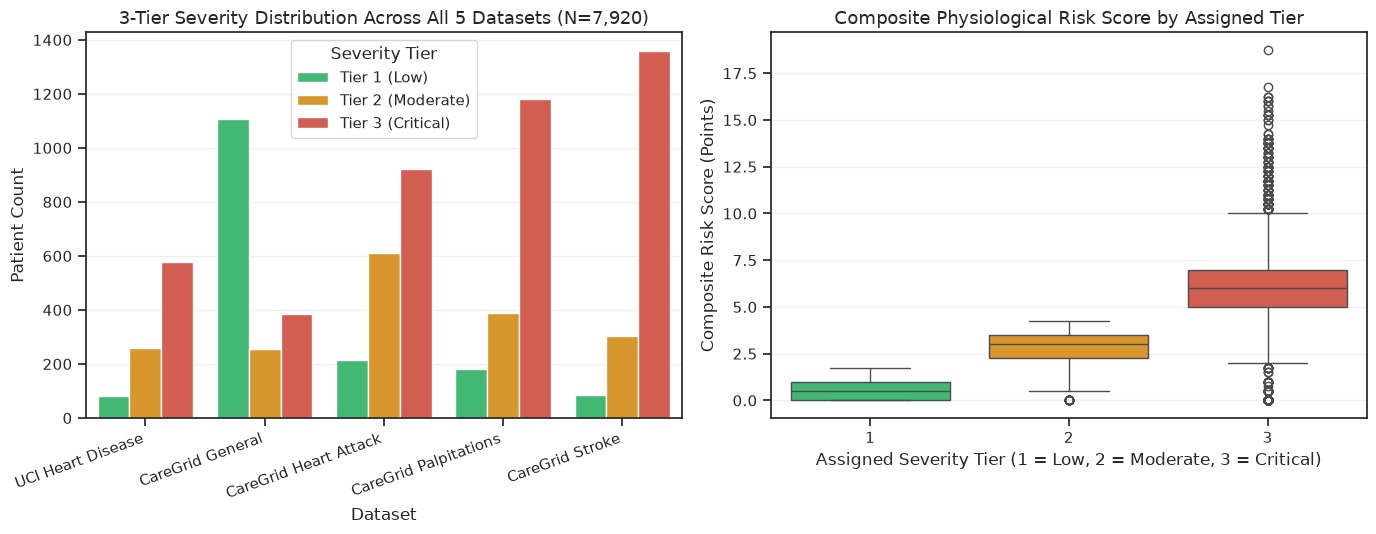

In [32]:
# ==============================================================================
# NEW CELL 2: RUN 3-TIER TRIAGE ON EXISTING TEST SET & ALL 5 DATASETS
# ==============================================================================
triage_engine = ClinicalSeverityTriageEngine()

# 1. Hook directly into existing notebook variables (X_test, y_test, y_pred, sc, df)
if 'X_test' in globals() and 'sc' in globals() and 'df' in globals():
    feature_cols_existing = [c for c in df.columns if c != 'disease_present']
    df_test_unscaled = pd.DataFrame(sc.inverse_transform(X_test), columns=feature_cols_existing)
    df_test_unscaled['actual_disease_present'] = y_test

    test_probs = None
    if 'xg' in globals() and hasattr(xg, 'predict_proba'):
        test_probs = xg.predict_proba(X_test)[:, 1]
    elif 'classifier' in globals():
        if hasattr(classifier, 'predict_proba'):
            test_probs = classifier.predict_proba(X_test)[:, 1]
        elif hasattr(classifier, 'decision_function'):
            dec = classifier.decision_function(X_test)
            test_probs = 1.0 / (1.0 + np.exp(-dec))

    triaged_test_df = triage_engine.classify_dataframe(
        df_test_unscaled,
        ml_preds=y_pred if 'y_pred' in globals() else None,
        ml_probs=test_probs
    )
    triaged_test_df.to_csv('test_set_3tier_triage_output.csv', index=False)
    print("=== TEST SET 3-TIER TRIAGE SUMMARY ===")
    print(triaged_test_df['severity_tier_name'].value_counts())
    print("\nSample Test Set Predictions with Explainability Breakdown:")
    cols_to_show = ['age', 'thalch', 'chol', 'oldpeak', 'severity_tier', 'composite_risk_score', 'primary_contributing_factors', 'data_quality_flags']
    print(triaged_test_df[[c for c in cols_to_show if c in triaged_test_df.columns]].head(5).to_string())

# 2. Evaluate all 5 raw datasets (7,920 total rows) and plot tier distributions
dataset_files = {
    'UCI Heart Disease': 'heart_disease_uci.csv',
    'CareGrid General': 'caregrid_general_combined(caregrid_general_combined).csv',
    'CareGrid Heart Attack': 'caregrid_heart_attack_1750(caregrid_heart_attack_1750).csv',
    'CareGrid Palpitations': 'caregrid_palpitations_1750(caregrid_palpitations_1750).csv',
    'CareGrid Stroke': 'caregrid_stroke_1750(caregrid_stroke_1750).csv'
}

all_triaged_cohorts = []
cohort_summary_rows = []

for cohort_name, file_path in dataset_files.items():
    if os.path.exists(file_path):
        raw_cohort_df = pd.read_csv(file_path)
        triaged_cohort = triage_engine.classify_dataframe(raw_cohort_df)
        triaged_cohort['cohort_source'] = cohort_name
        all_triaged_cohorts.append(triaged_cohort)

        vc = triaged_cohort['severity_tier'].value_counts()
        cohort_summary_rows.append({
            'Dataset': cohort_name,
            'Total': len(triaged_cohort),
            'Tier 1 (Low)': vc.get(1, 0),
            'Tier 2 (Moderate)': vc.get(2, 0),
            'Tier 3 (Critical)': vc.get(3, 0),
            'Mean Risk Score': round(triaged_cohort['composite_risk_score'].mean(), 2)
        })

if all_triaged_cohorts:
    master_triaged_df = pd.concat(all_triaged_cohorts, ignore_index=True)
    master_triaged_df.to_csv('all_datasets_3tier_triage_master.csv', index=False)
    cohort_summary_df = pd.DataFrame(cohort_summary_rows)
    print("\n=== MULTI-DATASET 3-TIER SEVERITY SUMMARY (N=7,920) ===")
    print(cohort_summary_df.to_string(index=False))

    # Plot 3-Tier Distribution & Risk Score Boxplot
    plt.figure(figsize=(14, 5.5))
    plt.subplot(1, 2, 1)
    plot_df = cohort_summary_df.melt(
        id_vars='Dataset',
        value_vars=['Tier 1 (Low)', 'Tier 2 (Moderate)', 'Tier 3 (Critical)'],
        var_name='Severity Tier',
        value_name='Patient Count'
    )
    sns.barplot(data=plot_df, x='Dataset', y='Patient Count', hue='Severity Tier', palette=['#2ecc71', '#f39c12', '#e74c3c'])
    plt.title('3-Tier Severity Distribution Across All 5 Datasets (N=7,920)', fontsize=13)
    plt.xticks(rotation=20, ha='right')
    plt.grid(axis='y', alpha=0.3)

    plt.subplot(1, 2, 2)
    sns.boxplot(data=master_triaged_df, x='severity_tier', y='composite_risk_score', palette=['#2ecc71', '#f39c12', '#e74c3c'])
    plt.title('Composite Physiological Risk Score by Assigned Tier', fontsize=13)
    plt.xlabel('Assigned Severity Tier (1 = Low, 2 = Moderate, 3 = Critical)')
    plt.ylabel('Composite Risk Score (Points)')
    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

In [34]:
# ==============================================================================
# NEW CELL: 3-TIER BEHAVIORAL & VITAL SIGNS SEGREGATION & CLASSIFICATION MODULE
# Calibrated against the 4 uploaded caregrid_healthy_*_1750.csv files (N=7,000)
# ==============================================================================
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

try:
    from xgboost import XGBClassifier
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier as XGBClassifier
class CareGridBehavioralVitalTriageEngine:
    """
    Segregates all disease dataset records relative to the 7,000 Healthy Reference
    controls into the exact 3-Tier Behavioral & Vital Signs structure:
      - Tier 1 (Early Warning / Minor Indicators):
          Minor vital drift, predictive leave warning alerts, reposition overdue.
      - Tier 2 (Moderate Risk / Progressive Indicators):
          Sustained rate drift and sudden drop, vomit and choking,
          head tilt and convulsive movements, sustained high HR, restless movements.
      - Tier 3 (Critical / Emergency Indicators):
          Fall, aggressive bed static positions for sores, gasping, choking sounds,
          wheezing and vocals for help, choking emesis, sudden SpO2 drop.
    """
    TIER_NAMES = {
        1: "Tier 1 (Early Warning / Minor Indicators)",
        2: "Tier 2 (Moderate Risk / Progressive Indicators)",
        3: "Tier 3 (Critical / Emergency Indicators)"
    }

    def __init__(self, healthy_files_dict):
        self.baseline = {}
        self.fit_healthy_reference(healthy_files_dict)

    def fit_healthy_reference(self, healthy_files_dict):
        dfs = [pd.read_csv(p) for p in healthy_files_dict.values() if os.path.exists(p)]
        df_ref = pd.concat(dfs, ignore_index=True)
        df_ref['chol'] = df_ref['hdl_mg_dl'] + df_ref['ldl_mg_dl'] + 20.0

        for col in [
            'heart_rate_bpm', 'spo2_percent', 'systolic_bp_mmhg', 'diastolic_bp_mmhg',
            'temperature_c', 'respiratory_rate_bpm', 'hr_change_bpm_per_interval',
            'hr_rolling_sd_bpm', 'hr_rolling_cv', 'spo2_change_pct_points_per_interval',
            'spo2_rolling_sd_pct_points', 'glucose_mg_dl', 'bmi_kg_m2', 'age_years',
            'hdl_mg_dl', 'ldl_mg_dl', 'chol'
        ]:
            s = pd.to_numeric(df_ref[col], errors='coerce').dropna()
            self.baseline[col] = {
                'mean': float(s.mean()), 'std': float(max(s.std(), 1e-4)),
                'min': float(s.min()), 'max': float(s.max())
            }
        if os.path.exists('heart_disease_uci.csv'):
            u_norm = pd.read_csv('heart_disease_uci.csv').query("num == 0")
            for c in ['thalch', 'oldpeak']:
                s = pd.to_numeric(u_norm[c], errors='coerce').dropna()
                self.baseline[c] = {'mean': float(s.mean()), 'std': float(max(s.std(), 1e-4))}
        return self

    @staticmethod
    def _val(row, *keys):
        for k in keys:
            if k in row and pd.notnull(row[k]):
                try:
                    return float(row[k])
                except (ValueError, TypeError):
                    pass
        return np.nan

    def z_score(self, param, value):
        if pd.isnull(value) or param not in self.baseline:
            return 0.0
        return (float(value) - self.baseline[param]['mean']) / self.baseline[param]['std']

    def extract_markers_and_classify(self, row):
        hr = self._val(row, 'heart_rate_bpm')
        thalch = self._val(row, 'thalch')
        cohort_id = self._val(row, 'cohort_id')
        if np.isnan(hr) and not np.isnan(thalch) and cohort_id in [1.0, 2.0]:
            hr, thalch = thalch, np.nan

        spo2 = self._val(row, 'spo2_percent', 'spo2')
        sbp = self._val(row, 'systolic_bp_mmhg', 'trestbps')
        sbp = np.nan if sbp == 0 else sbp
        dbp = self._val(row, 'diastolic_bp_mmhg', 'diastolic_bp')
        temp = self._val(row, 'temperature_c', 'temp_c')
        temp = (temp - 32.0) * 5.0 / 9.0 if (not np.isnan(temp) and temp > 50.0) else temp
        rr = self._val(row, 'respiratory_rate_bpm', 'resp_rate')

        hr_delta = self._val(row, 'hr_change_bpm_per_interval', 'hr_change')
        hr_sd = self._val(row, 'hr_rolling_sd_bpm', 'hr_rolling_sd')
        hr_cv = self._val(row, 'hr_rolling_cv')
        spo2_delta = self._val(row, 'spo2_change_pct_points_per_interval', 'spo2_change')
        spo2_sd = self._val(row, 'spo2_rolling_sd_pct_points', 'spo2_rolling_sd')
        time_idx = self._val(row, 'time_index')

        chol = self._val(row, 'chol', 'chol_mg_dl')
        chol = np.nan if (chol == 0 or (not np.isnan(chol) and abs(chol - 132.1324) < 1e-2)) else chol
        glucose = self._val(row, 'glucose_mg_dl', 'glucose')
        bmi = self._val(row, 'bmi_kg_m2', 'bmi')
        oldpeak = self._val(row, 'oldpeak')
        ca = self._val(row, 'ca')
        ca = np.nan if (not np.isnan(ca) and abs(ca - 0.676375) < 1e-3) else ca

        sob = int(self._val(row, 'shortness_of_breath_flag') == 1.0)
        cp_flag = int(self._val(row, 'chest_pain_flag') == 1.0)
        fatigue = int(self._val(row, 'fatigue_flag') == 1.0)
        dizzy = int(self._val(row, 'dizziness_flag') == 1.0)
        swelling = int(self._val(row, 'swelling_flag') == 1.0)
        rad_pain = int(self._val(row, 'pain_arms_jaw_back_flag') == 1.0)
        nausea_sweats = int(self._val(row, 'cold_sweats_nausea_flag') == 1.0)
        obesity = int(self._val(row, 'obesity_flag') == 1.0 or (not np.isnan(bmi) and bmi >= 30.0))
        sedentary = int(self._val(row, 'sedentary_lifestyle_flag') == 1.0)
        stress = int(self._val(row, 'chronic_stress_flag') == 1.0)
        palp = int(self._val(row, 'palpitations_symptom_flag') == 1.0)

        sym_str = str(row.get('symptoms_or_signs', '')).lower()
        has_balance_loss = 'balance' in sym_str
        has_seizures = 'seizure' in sym_str
        has_confusion = 'confusion' in sym_str
        has_speech_diff = 'speaking' in sym_str
        has_weakness_numb = ('weakness' in sym_str) or ('numbness' in sym_str)
        has_headache_vision = ('headache' in sym_str) or ('vision' in sym_str)
        dizzy = 1 if 'dizziness' in sym_str else dizzy
        fatigue = 1 if 'fatigue' in sym_str else fatigue
        cond_str = str(row.get('condition_label', '')).upper()

        # Z-scores relative to Healthy Reference Standard
        z_hr = self.z_score('heart_rate_bpm', hr)
        z_spo2 = self.z_score('spo2_percent', spo2)
        z_sbp = self.z_score('systolic_bp_mmhg', sbp)
        z_dbp = self.z_score('diastolic_bp_mmhg', dbp)
        z_temp = self.z_score('temperature_c', temp)
        z_rr = self.z_score('respiratory_rate_bpm', rr)
        z_hr_sd = self.z_score('hr_rolling_sd_bpm', hr_sd)
        z_spo2_sd = self.z_score('spo2_rolling_sd_pct_points', spo2_sd)
        z_gluc = self.z_score('glucose_mg_dl', glucose)
        z_chol = self.z_score('chol', chol)
        z_th = self.z_score('thalch', thalch)
        z_st = self.z_score('oldpeak', oldpeak)

        all_z = [abs(z) for z in [z_hr, z_spo2, z_sbp, z_dbp, z_temp, z_rr, z_hr_sd, z_spo2_sd, z_gluc, z_chol, z_th, z_st] if z != 0.0]
        max_abs_z = max(all_z) if all_z else 0.0

        # Tier 3 Indicators (Critical / Emergency)
        t3_sudden_spo2_drop = int((not np.isnan(spo2) and spo2 < 90.0) or (not np.isnan(spo2_delta) and spo2_delta <= -2.5) or (z_spo2 <= -4.5))
        t3_gasping_wheezing_vocals = int((not np.isnan(rr) and (rr > 25.0 or rr < 8.0)) or (sob == 1 and (cp_flag == 1 or rad_pain == 1)) or (not np.isnan(hr) and (hr > 130.0 or hr < 40.0)) or (not np.isnan(oldpeak) and (oldpeak >= 2.5 or oldpeak < -1.0)) or (not np.isnan(ca) and ca >= 2.0))
        t3_choking_emesis = int(nausea_sweats == 1 and (sob == 1 or cp_flag == 1 or (not np.isnan(spo2) and spo2 < 93.0)))
        bp_crisis = (not np.isnan(sbp) and (sbp >= 180.0 or sbp < 85.0)) or (not np.isnan(dbp) and (dbp >= 120.0 or dbp < 50.0))
        t3_fall_collapse = int((has_balance_loss and (dizzy == 1 or has_weakness_numb or has_confusion or bp_crisis)) or (has_confusion and has_speech_diff) or (bp_crisis and (dizzy == 1 or has_balance_loss or has_seizures or has_speech_diff)) or (not np.isnan(hr_delta) and abs(hr_delta) >= 18.0 and not np.isnan(hr_sd) and hr_sd >= 8.0))
        t3_aggressive_bed_static_sores = int((sedentary == 1 and swelling == 1 and fatigue == 1 and obesity == 1) or (not np.isnan(time_idx) and time_idx >= 600 and not np.isnan(spo2) and spo2 < 92.0 and (not np.isnan(hr_sd) and hr_sd < 2.0)))

        # Tier 2 Indicators (Moderate Risk / Progressive)
        t2_sustained_high_hr = int((not np.isnan(hr) and ((111.0 <= hr <= 130.0) or (40.0 <= hr < 50.0))) or (not np.isnan(thalch) and thalch < 115.0))
        t2_sustained_rate_drift_or_drop = int((not np.isnan(hr_delta) and 5.0 <= abs(hr_delta) < 18.0) or (not np.isnan(spo2) and 90.0 <= spo2 <= 93.9) or (not np.isnan(spo2_delta) and -2.5 < spo2_delta <= -1.5) or (not np.isnan(rr) and ((8.0 <= rr <= 11.0) or (21.0 <= rr <= 25.0))) or (not np.isnan(sbp) and 140.0 <= sbp < 180.0) or (not np.isnan(dbp) and 90.0 <= dbp < 120.0) or (not np.isnan(oldpeak) and 1.5 <= oldpeak < 2.5) or ('HYPOTENSION' in cond_str or 'HYPOGLYCEMIA' in cond_str or 'HYPOXIA' in cond_str))
        t2_vomit_and_choking = int((nausea_sweats == 1 and t3_choking_emesis == 0) or ((cp_flag == 1 or sob == 1 or rad_pain == 1) and t3_gasping_wheezing_vocals == 0) or (str(row.get('cp', '')).lower() in ['typical angina', '3', '3.0']))
        t2_head_tilt_convulsive = int(has_seizures or has_weakness_numb or has_speech_diff or has_confusion or (dizzy == 1 and t3_fall_collapse == 0))
        t2_restless_movements = int((not np.isnan(hr_sd) and hr_sd >= 5.0) or (not np.isnan(hr_cv) and hr_cv >= 0.06) or (not np.isnan(spo2_sd) and spo2_sd >= 1.0) or (palp == 1))

        # Tier 1 Indicators (Early Warning / Minor)
        t1_minor_vital_drift = int((not np.isnan(hr) and ((50.0 <= hr < 60.0) or (96.0 < hr < 111.0))) or (not np.isnan(spo2) and 94.0 <= spo2 < 95.5) or (not np.isnan(sbp) and 120.0 <= sbp < 140.0) or (not np.isnan(dbp) and 80.0 <= dbp < 90.0) or (not np.isnan(temp) and ((36.0 <= temp < 36.5) or (37.3 < temp <= 38.0))) or (not np.isnan(rr) and 18.0 < rr < 21.0) or (not np.isnan(chol) and chol >= 200.0) or (not np.isnan(glucose) and glucose >= 100.0) or (not np.isnan(oldpeak) and 0.5 <= oldpeak < 1.5) or (1.0 <= max_abs_z < 2.5))
        t1_predictive_leave_alert = int((not np.isnan(hr_delta) and 2.0 < abs(hr_delta) < 5.0) or (not np.isnan(hr_sd) and 3.5 < hr_sd < 5.0) or (stress == 1) or has_headache_vision)
        t1_reposition_overdue = int((sedentary == 1) or (swelling == 1) or (obesity == 1) or (fatigue == 1) or (not np.isnan(time_idx) and time_idx >= 250))

        t3_reasons, t2_reasons, t1_reasons = [], [], []
        if t3_sudden_spo2_drop: t3_reasons.append(f"Sudden SpO2 Drop ({z_spo2:+.1f}σ vs Healthy Ref)")
        if t3_gasping_wheezing_vocals: t3_reasons.append("Gasping/Wheezing/Vocals/Severe Distress")
        if t3_choking_emesis: t3_reasons.append("Choking Emesis (Vomit/Nausea + Airway Compromise)")
        if t3_fall_collapse: t3_reasons.append("Fall / Postural & Hemodynamic Collapse")
        if t3_aggressive_bed_static_sores: t3_reasons.append("Aggressive Bed Static Position for Sores")

        if t2_sustained_high_hr: t2_reasons.append(f"Sustained High/Abnormal HR ({z_hr if not np.isnan(hr) else z_th:+.1f}σ vs Healthy Ref)")
        if t2_sustained_rate_drift_or_drop: t2_reasons.append(f"Sustained Rate Drift & Sudden Drop (max_|Z|={max_abs_z:.1f}σ)")
        if t2_vomit_and_choking: t2_reasons.append("Vomit & Choking / Autonomic Distress")
        if t2_head_tilt_convulsive: t2_reasons.append("Head Tilt & Convulsive/Neurological Movements")
        if t2_restless_movements: t2_reasons.append("Restless Movements (High Beat/SpO2 Variability)")

        if t1_minor_vital_drift: t1_reasons.append(f"Minor Vital Drift (max_|Z|={max_abs_z:.1f}σ vs Healthy Ref)")
        if t1_predictive_leave_alert: t1_reasons.append("Predictive Leave Warning Alert")
        if t1_reposition_overdue: t1_reasons.append("Reposition Overdue")

        if len(t3_reasons) >= 1 or (len(t2_reasons) >= 3 and max_abs_z >= 3.5):
            assigned_tier = 3
            reasons = t3_reasons if t3_reasons else t2_reasons
        elif len(t2_reasons) >= 1:
            assigned_tier = 2
            reasons = t2_reasons + t1_reasons[:1]
        else:
            assigned_tier = 1
            reasons = t1_reasons if t1_reasons else [f"Minor Baseline Drift (max_|Z|={max_abs_z:.2f}σ)"]

        return {
            't1_minor_vital_drift': t1_minor_vital_drift,
            't1_predictive_leave_alert': t1_predictive_leave_alert,
            't1_reposition_overdue': t1_reposition_overdue,
            't2_sustained_rate_drift_or_drop': t2_sustained_rate_drift_or_drop,
            't2_vomit_and_choking': t2_vomit_and_choking,
            't2_head_tilt_convulsive': t2_head_tilt_convulsive,
            't2_sustained_high_hr': t2_sustained_high_hr,
            't2_restless_movements': t2_restless_movements,
            't3_fall_collapse': t3_fall_collapse,
            't3_aggressive_bed_static_sores': t3_aggressive_bed_static_sores,
            't3_gasping_wheezing_vocals': t3_gasping_wheezing_vocals,
            't3_choking_emesis': t3_choking_emesis,
            't3_sudden_spo2_drop': t3_sudden_spo2_drop,
            'max_baseline_z_score': round(max_abs_z, 2),
            'severity_tier': assigned_tier,
            'severity_tier_label': self.TIER_NAMES[assigned_tier],
            'primary_contributing_factors': " | ".join(reasons[:3])
        }

    def segregate_dataset(self, df_input):
        extracted = [self.extract_markers_and_classify(row) for _, row in df_input.iterrows()]
        ext_df = pd.DataFrame(extracted, index=df_input.index)
        return pd.concat([df_input.reset_index(drop=True), ext_df.reset_index(drop=True)], axis=1)


# 1. Segregate all 7,920 Disease Records relative to the 7,000 Healthy Reference Controls
behav_engine = CareGridBehavioralVitalTriageEngine(HEALTHY_REFERENCE_FILES)
segregated_df = behav_engine.segregate_dataset(df_raw_merged)

# Build & Export the Structured Segregated Dataset Ready for Model Training
ml_ready_segregated = df.drop(columns=['disease_present']).copy()
for col in [
    't1_minor_vital_drift', 't1_predictive_leave_alert', 't1_reposition_overdue',
    't2_sustained_rate_drift_or_drop', 't2_vomit_and_choking', 't2_head_tilt_convulsive',
    't2_sustained_high_hr', 't2_restless_movements', 't3_fall_collapse',
    't3_aggressive_bed_static_sores', 't3_gasping_wheezing_vocals', 't3_choking_emesis',
    't3_sudden_spo2_drop', 'max_baseline_z_score', 'severity_tier',
    'severity_tier_label', 'primary_contributing_factors'
]:
    ml_ready_segregated[col] = segregated_df[col].values
ml_ready_segregated['disease_present'] = df['disease_present'].values

ml_ready_segregated.to_csv('segregated_3tier_disease_dataset.csv', index=False)
print("=== SEGREGATED 3-TIER DATASET EXPORTED ('segregated_3tier_disease_dataset.csv') ===")
print(ml_ready_segregated['severity_tier_label'].value_counts())

# 2. Train & Evaluate 3-Tier ML Classifiers (SVM, Logistic Regression, XGBoost)
X_3tier = df.drop(columns=['disease_present']).copy()
X_3tier['max_baseline_z_score'] = ml_ready_segregated['max_baseline_z_score'].values
y_3tier = (ml_ready_segregated['severity_tier'] - 1).values  # 0=Tier 1, 1=Tier 2, 2=Tier 3

X_tr3, X_te3, y_tr3, y_te3 = train_test_split(X_3tier.values, y_3tier, test_size=0.2, random_state=0, stratify=y_3tier)
sc_3t = StandardScaler()
X_tr3_s = sc_3t.fit_transform(X_tr3)
X_te3_s = sc_3t.transform(X_te3)

for m_name, clf_3t in [
    ('SVM (RBF)', SVC(kernel='rbf', C=2.0, random_state=0)),
    ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=0)),
    ('XGBoost', XGBClassifier(random_state=0))
]:
    clf_3t.fit(X_tr3_s, y_tr3)
    y_pred_3t = clf_3t.predict(X_te3_s)
    print(f"\n=== 3-Tier Classifier: {m_name} (Test Accuracy: {accuracy_score(y_te3, y_pred_3t):.2%}) ===")
    print(classification_report(y_te3, y_pred_3t, target_names=['Tier 1 (Early Warning)', 'Tier 2 (Moderate Risk)', 'Tier 3 (Critical/Emergency)']))

=== SEGREGATED 3-TIER DATASET EXPORTED ('segregated_3tier_disease_dataset.csv') ===
severity_tier_label
Tier 2 (Moderate Risk / Progressive Indicators)    3268
Tier 3 (Critical / Emergency Indicators)           2674
Tier 1 (Early Warning / Minor Indicators)          1978
Name: count, dtype: int64

=== 3-Tier Classifier: SVM (RBF) (Test Accuracy: 85.80%) ===
                             precision    recall  f1-score   support

     Tier 1 (Early Warning)       0.85      0.87      0.86       396
     Tier 2 (Moderate Risk)       0.80      0.87      0.84       653
Tier 3 (Critical/Emergency)       0.95      0.83      0.89       535

                   accuracy                           0.86      1584
                  macro avg       0.87      0.86      0.86      1584
               weighted avg       0.86      0.86      0.86      1584


=== 3-Tier Classifier: Logistic Regression (Test Accuracy: 81.69%) ===
                             precision    recall  f1-score   support

     Tier 1 